In [24]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt


from sklearn.model_selection import GridSearchCV
from sklearn.metrics import f1_score

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier

from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    classification_report
)

from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import seaborn as sns

In [9]:
from google.colab import files
uploaded = files.upload()

Saving steam-200k.csv to steam-200k.csv


In [25]:
df = pd.read_csv('steam-200k.csv')
df.head(5)

,151603712,The Elder Scrolls V Skyrim,purchase,1.0,0
0,151603712,The Elder Scrolls V Skyrim,play,273.0,0
1,151603712,Fallout 4,purchase,1.0,0
2,151603712,Fallout 4,play,87.0,0
3,151603712,Spore,purchase,1.0,0
4,151603712,Spore,play,14.9,0


In [26]:
df = pd.read_csv('steam-200k.csv', header=None)

df.columns = [
    "user_id",
    "game",
    "behavior",
    "value",
    "unused"
]

In [27]:
df.head(5)

,user_id,game,behavior,value,unused
0,151603712,The Elder Scrolls V Skyrim,purchase,1.0,0
1,151603712,The Elder Scrolls V Skyrim,play,273.0,0
2,151603712,Fallout 4,purchase,1.0,0
3,151603712,Fallout 4,play,87.0,0
4,151603712,Spore,purchase,1.0,0


In [28]:
df.shape

(200000, 5)

In [29]:
df.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200000 entries, 0 to 199999
Data columns (total 5 columns):
 #   Column    Non-Null Count   Dtype  
---  ------    --------------   -----  
 0   user_id   200000 non-null  int64  
 1   game      200000 non-null  object 
 2   behavior  200000 non-null  object 
 3   value     200000 non-null  float64
 4   unused    200000 non-null  int64  
dtypes: float64(1), int64(2), object(2)
memory usage: 7.6+ MB


In [30]:
df.isnull().sum()

,0
user_id,0
game,0
behavior,0
value,0
unused,0


In [31]:
df.duplicated().sum()

np.int64(707)

In [32]:
df = df.drop_duplicates()

In [33]:
df.describe()

,user_id,value,unused
count,1.992930e+05,199293.000000,199293.0
mean,1.037181e+08,17.934247,0.0
std,7.212048e+07,138.297952,0.0
min,5.250000e+03,0.100000,0.0
25%,4.738430e+07,1.000000,0.0
50%,8.691201e+07,1.000000,0.0
75%,1.542309e+08,1.400000,0.0
max,3.099031e+08,11754.000000,0.0


In [34]:
df['value'].describe()

,value
count,199293.000000
mean,17.934247
std,138.297952
min,0.100000
25%,1.000000
50%,1.000000
75%,1.400000
max,11754.000000


In [35]:
df['behavior'].value_counts()

,count
behavior,
purchase,128804
play,70489


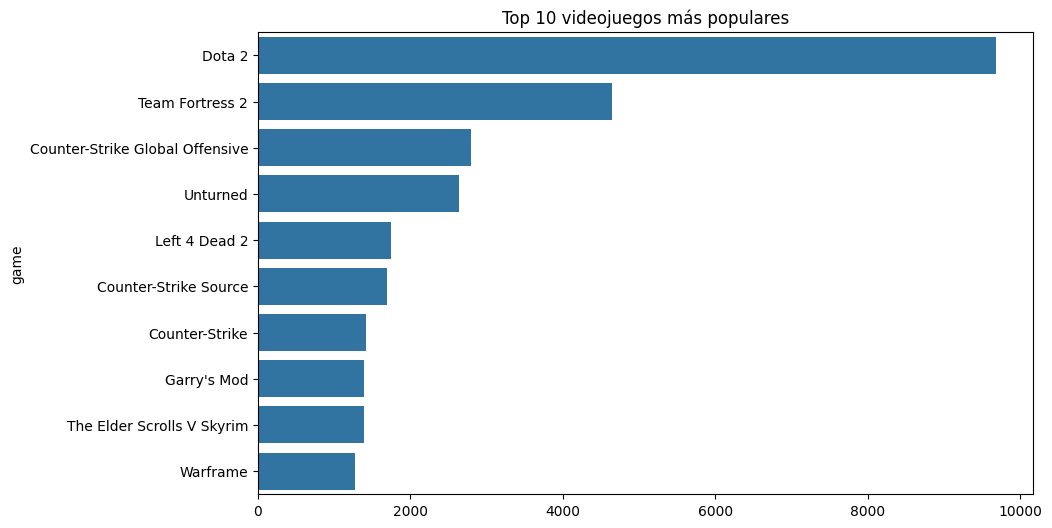

In [36]:
top_games = df['game'].value_counts().head(10)

plt.figure(figsize=(10,6))
sns.barplot(
    x=top_games.values,
    y=top_games.index
)

plt.title('Top 10 videojuegos más populares')
plt.show()

In [37]:
usuarios_activos = (
    df[df['behavior']=='play']
    .groupby('user_id')['value']
    .sum()
    .sort_values(ascending=False)
    .head(10)
)

usuarios_activos

,value
user_id,
73017395,11754.0
10599862,11651.7
100630947,10853.2
26762388,10470.1
153382649,9640.0
43684632,9546.3
48798067,9427.2
52731290,9417.6
42935819,8172.9


In [40]:
user_features = df.pivot_table(
    index='user_id',
    columns='behavior',
    values='value',
    aggfunc='sum',
    fill_value=0
)

user_features.head()

behavior,play,purchase
user_id,,
5250,225.5,21.0
76767,1227.0,36.0
86540,255.0,82.0
103360,0.0,10.0
144736,0.1,8.0


In [41]:
games_count = (
    df.groupby('user_id')['game']
    .nunique()
)

user_features['num_games'] = games_count

In [42]:
user_features.head()

behavior,play,purchase,num_games
user_id,,,
5250,225.5,21.0,21
76767,1227.0,36.0,36
86540,255.0,82.0,82
103360,0.0,10.0,10
144736,0.1,8.0,8


In [43]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X = scaler.fit_transform(user_features)

In [44]:
from sklearn.cluster import KMeans

inertia = []

for k in range(1,11):
    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    model.fit(X)

    inertia.append(model.inertia_)

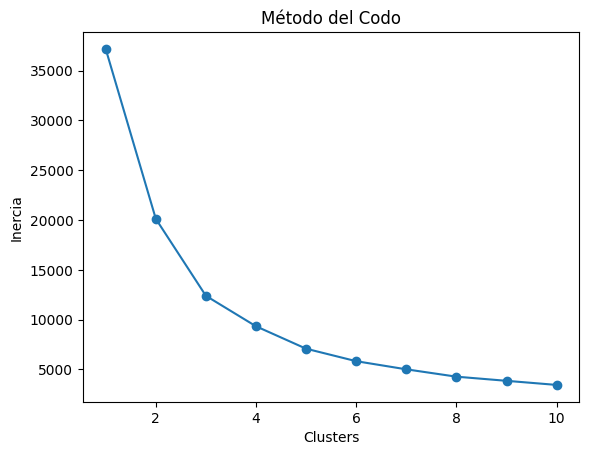

In [45]:
plt.plot(
    range(1,11),
    inertia,
    marker='o'
)

plt.xlabel('Clusters')
plt.ylabel('Inercia')
plt.title('Método del Codo')
plt.show()

In [46]:
kmeans = KMeans(
    n_clusters=4,
    random_state=42,
    n_init=10
)

clusters = kmeans.fit_predict(X)

user_features['cluster'] = clusters

In [47]:
from sklearn.decomposition import PCA

pca = PCA(n_components=2)

components = pca.fit_transform(X)

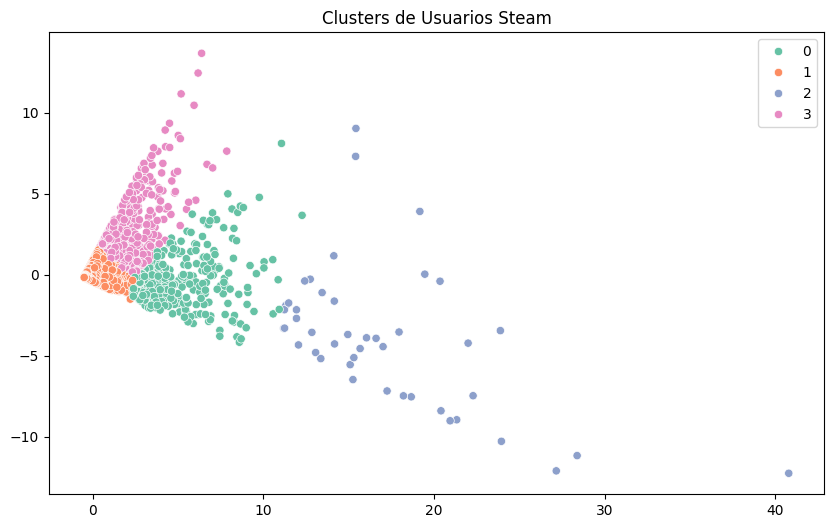

In [48]:
plt.figure(figsize=(10,6))

sns.scatterplot(
    x=components[:,0],
    y=components[:,1],
    hue=clusters,
    palette='Set2'
)

plt.title("Clusters de Usuarios Steam")
plt.show()

In [49]:
cluster_summary = (
    user_features
    .groupby('cluster')
    .mean()
)

cluster_summary

behavior,play,purchase,num_games
cluster,,,
0,1770.145048,127.626198,127.626198
1,114.177540,4.811901,4.811901
2,3389.434091,439.750000,439.750000
3,2565.672939,25.586022,25.586022


##Recomendaciones de negocio
Con base en los segmentos encontrados, responde:
    • Qué estrategia de marketing implementarías para cada grupo?
    • Qué tipo de promociones recibiría cada segmento?
    • Qué usuarios priorizarías para campañas de fidelización?
Qué información adicional sería útil para mejorar la segmentación?

Para Jugadores Casual

✅ Cupones de descuento

✅ Juegos gratuitos temporales

✅ Correos de reactivación

Para Compradores Frecuentes

✅ Recomendaciones mediante IA

✅ Promociones cruzadas

✅ Bundles

Para una mejor interpretacion seria muy bueno tener informacion como:

Edad del jugador.
País.
Género preferido de videojuegos.
Fecha de registro.
Frecuencia de compra.
Gasto monetario real.
Participación en eventos.
Datos de amigos o comunidad.